# Topic Analysis - Research Document Mining
Search engines index thousands of new research publications each year, making it increasingly challenging for researchers
and analysts to identify emerging trends and monitor the evolution of research topics. To address this challenge, you have
been tasked with designing a prototype system for tracking research trends in the field of artificial intelligence. As a proof of
concept, the system will apply topic modelling techniques to a small collection of recent AI research articles provided in the
research_corpus.zip dataset, with the aim of uncovering the main themes and research directions represented in the corpus.


In [19]:
# load libraries
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import LatentDirichletAllocation

In [20]:
# load data
path = Path("../data")

files = sorted(path.glob("research_[1-5].txt"))

corpus = pd.DataFrame([
    {
        "article_id": file.stem,
        "content": file.read_text(encoding="utf-8-sig")
    }
    for file in files
])

In [21]:
# inspect data
corpus["word_count"] = corpus["content"].str.split().str.len()
corpus["character_count"] = corpus["content"].str.len()

print(corpus[["article_id", "word_count", "character_count"]].to_string(index=False))

article_id  word_count  character_count
research_1        5602            38160
research_2        2416            16104
research_3        3828            26154
research_4        5922            38950
research_5        4027            26831


In [22]:
# preprocess text
def clean_article(text):
    text = re.sub(r'https?://\S+|www\.\S+|\S+@\S+', ' ', text)
    text = re.sub(r'\b(?:references|bibliography)\b.*$', ' ', text,
                  flags=re.IGNORECASE | re.DOTALL) if re.search(
                      r'(?im)^\s*(?:references|bibliography)\s*$', text) else text
    text = re.sub(r'\s+', ' ', text).strip()
    return text

corpus['cleaned_content'] = corpus['content'].map(clean_article)
print(corpus[['article_id', 'word_count']].to_string(index=False))
print('First cleaned article excerpt:', corpus.loc[0, 'cleaned_content'][:400])
# save corpus for Question 4
corpus.to_csv("../data/processed/cleaned_research_corpus.csv", index=False, encoding='utf-8')



article_id  word_count
research_1        5602
research_2        2416
research_3        3828
research_4        5922
research_5        4027
First cleaned article excerpt: The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting mixed methods research. In doing this, we briefly review the paradig


FIRST ARTICLE SUMMARY:
 A few examples of subjectivism and intersubjectivism in quantitative research include deciding what to study (i.e., what are the important problems?), developing instruments that are believed to measure what the researcher views as being the target construct, choosing the 16 EDUCATIONAL RESEARCHER specific tests and items for measurement, making score interpretations, selecting alpha levels (e.g., .05), drawing conclusions and interpretations based on the collected data, deciding what elements of the data to emphasize or publish, and deciding what findings are practically significant.
Basic agreement has been reached on each of the following issues: (a) the relativity of the “light of reason” (i.e., what appears reasonable can vary across persons); (b) theory-laden perception or the theory-ladenness of facts (i.e., what we notice and observe is affected by our background knowledge, theories, and experiences; in short, observation is not a perfect and direct wind

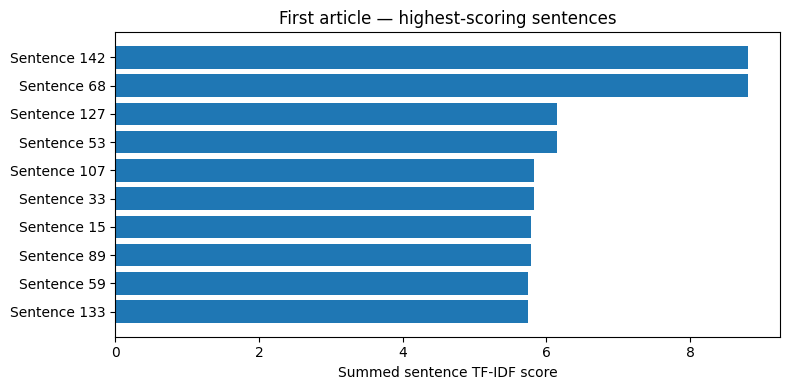

In [23]:
# summarise first article
def split_sentences(text):
    return [s.strip() for s in re.split(r'(?<=[.!?])\s+(?=[A-Z])', text)
            if len(s.split()) >= 8]

def extractive_summary(text, count=5):
    sentences = split_sentences(text)
    if not sentences:
        return [], []
    matrix = TfidfVectorizer(stop_words='english').fit_transform(sentences)
    scores = np.asarray(matrix.sum(axis=1)).ravel()
    selected = sorted(np.argsort(scores)[-min(count, len(sentences)):])
    return [sentences[i] for i in selected], [(i + 1, scores[i]) for i in np.argsort(scores)[-10:][::-1]]

first_summary, sentence_ranks = extractive_summary(corpus.loc[0, 'cleaned_content'])
print('FIRST ARTICLE SUMMARY:\n', '\n'.join(first_summary))
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh([f'Sentence {i}' for i, _ in sentence_ranks][::-1],
        [score for _, score in sentence_ranks][::-1])
ax.set_xlabel('Summed sentence TF-IDF score')
ax.set_title('First article — highest-scoring sentences')
plt.tight_layout()
plt.show()

AGGREGATE SUMMARY:

research_2: Reflexivity has been increasingly recognized as a crucial strategy in the process of generating knowledge by means of qualitative research (Ahmed Dunya et al., 2011; Blaxter et al., 2006; D’Cruz et al., 2007; Gerstl-Pepin and Patrizion, 2009; Hammersley and Atkinson, 2002; Horsburgh, 2003; Koch and Harrington, 1998).For example, the journal Forum: Qualitative Research dedicated a full issue (May 2003) to subjectivity and reflexivity in qualitative research, and there Corresponding author: Roni Berger, School of Social Work, Adelphi University, 1 South Avenue, Garden City, NY 11530, USA.

research_3: DEVELOPMENTAL RESEARCH: STUDIES OF INSTRUCTIONAL DESIGN AND DEVELOPMENT Rita C.

research_4: The Use of Cronbach’s Alpha in Science Education Studies It is common to see the reliability of instruments used in published science education studies framed in terms of a statistic known as Cronbach’s alpha (Cronbach, 1951).

research_5: Keywords: triangulation, Den

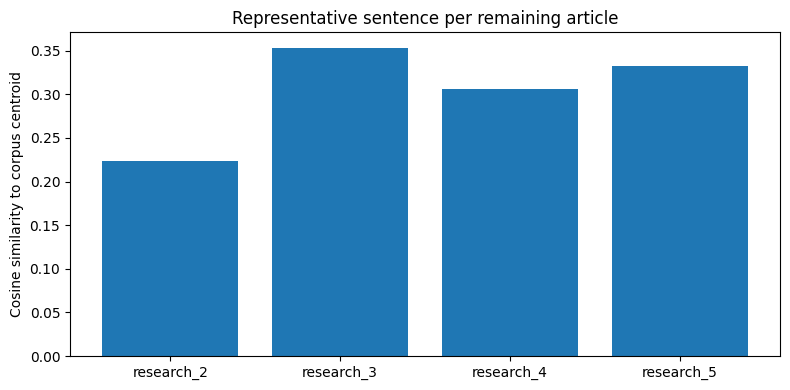

In [24]:
# summarise remaining articles
from sklearn.metrics.pairwise import cosine_similarity
remaining = corpus.iloc[1:].copy()
rows = [(article_id, sentence)
        for article_id, text in zip(remaining['article_id'], remaining['cleaned_content'])
        for sentence in split_sentences(text)]
sentence_df = pd.DataFrame(rows, columns=['article_id', 'sentence'])
vectorizer = TfidfVectorizer(stop_words='english', min_df=2)
sentence_matrix = vectorizer.fit_transform(sentence_df['sentence'])
centroid = np.asarray(sentence_matrix.mean(axis=0))
sentence_df['centrality'] = cosine_similarity(sentence_matrix, centroid).ravel()
aggregate_summary = (sentence_df.sort_values('centrality', ascending=False)
                     .drop_duplicates('article_id')
                     .sort_values('article_id'))
print('AGGREGATE SUMMARY:\n')
for row in aggregate_summary.itertuples():
    print(f'{row.article_id}: {row.sentence}\n')
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(aggregate_summary['article_id'], aggregate_summary['centrality'])
ax.set_ylabel('Cosine similarity to corpus centroid')
ax.set_title('Representative sentence per remaining article')
plt.tight_layout()
plt.show()